In [ ]:
import sys
import json
import requests
from prettytable import PrettyTable

# Documentation: https://www.uniprot.org/help/api
WEBSITE_API = "https://rest.uniprot.org/"

# Documentation: https://www.ebi.ac.uk/proteins/api/doc/
PROTEINS_API = "https://www.ebi.ac.uk/proteins/api"

# Helper function to download data
def get_url(url, **kwargs):
  response = requests.get(url, **kwargs);

  if not response.ok:
    print(response.text)
    response.raise_for_status()
    sys.exit()

  return response

In [ ]:
r = get_url(f"{WEBSITE_API}/uniprotkb/search?query=*")

data = r.json()

# print the number of results in the payload
n_results = len(data["results"])
print(f"Number of results: {n_results}\n")

# print all headers in the server response
table = PrettyTable()
headers = dict(sorted(r.headers.items()))
table.add_column("Header", list(headers.keys()))
table.add_column("Value", list(headers.values()))
table.align = "l"
print(table)

Number of results: 25

+----------------------------------+-----------------------------------------------------------------------------------------------------------------------+
| Header                           | Value                                                                                                                 |
+----------------------------------+-----------------------------------------------------------------------------------------------------------------------+
| Accept-Ranges                    | bytes                                                                                                                 |
| Access-Control-Allow-Credentials | true                                                                                                                  |
| Access-Control-Allow-Headers     | DNT,Keep-Alive,User-Agent,X-Requested-With,If-Modified-Since,Cache-Control,Content-Type,Range,Authorization           |
| Access-Control-Allow-Methods     

In [ ]:
# Search for gene Fam19A5, in human
url = f"{WEBSITE_API}/uniprotkb/search?query=Fam19A5 AND (taxonomy_id:9606)"

# while there are next pages, paginate through them
tally = 0
while url:
  r = get_url(url)
  data = r.json()
  total = r.headers.get("x-total-results")
  tally += len(data["results"])
  print(f"{tally:<3} / {total} | {url}")

  # Get next url from r.links.next.url handily provided by Requests from r.headers["Link"]
  url = r.links.get("next", {}).get("url")

4   / 4 | https://rest.uniprot.org//uniprotkb/search?query=Fam19A5 AND (taxonomy_id:9606)


In [ ]:
# stream good for simplicity (no pagination), but...
#  - harder to follow progress
#  - harder to resume on failure
#  - not sorted by score
#  - limited to <10M entries
r = get_url(f"{WEBSITE_API}/uniprotkb/stream?query=Fam19A5 AND (taxonomy_id:9606)")

data = r.json()

total = len(data["results"])
print(f"total: {total}")

total: 4


In [ ]:
# For all supported formats see https://www.uniprot.org/help/api_queries#list-of-all-formats

# No format defined, defaults to JSON
# r = get_url(f"{WEBSITE_API}/uniprotkb/search?query=Fam19A5 AND (taxonomy_id:9606)&size=1")

# XML - specify format explicitely in the URL
# r = get_url(f"{WEBSITE_API}/uniprotkb/search?query=Fam19A5 AND (taxonomy_id:9606)&size=1&format=xml")

# XML - specify format using request headers
# r = get_url(f"{WEBSITE_API}/uniprotkb/search?query=Fam19A5 AND (taxonomy_id:9606)&size=1", headers={"Accept": "application/xml"})

# Accession list
# r = get_url(f"{WEBSITE_API}/uniprotkb/search?query=Fam19A5 AND (taxonomy_id:9606)&format=list")

# FASTA
# r = get_url(f"{WEBSITE_API}/uniprotkb/search?query=Fam19A5 AND (taxonomy_id:9606)&format=fasta")

# TSV
# r = get_url(f"{WEBSITE_API}/uniprotkb/search?query=Fam19A5 AND (taxonomy_id:9606)&format=tsv")

print(r.text)

{"results":[{"entryType":"UniProtKB reviewed (Swiss-Prot)","primaryAccession":"O95136","secondaryAccessions":["Q86UN8"],"uniProtkbId":"S1PR2_HUMAN","entryAudit":{"firstPublicDate":"2003-11-07","lastAnnotationUpdateDate":"2025-06-18","lastSequenceUpdateDate":"2003-11-07","entryVersion":188,"sequenceVersion":2},"annotationScore":5.0,"organism":{"scientificName":"Homo sapiens","commonName":"Human","taxonId":9606,"lineage":["Eukaryota","Metazoa","Chordata","Craniata","Vertebrata","Euteleostomi","Mammalia","Eutheria","Euarchontoglires","Primates","Haplorrhini","Catarrhini","Hominidae","Homo"]},"proteinExistence":"1: Evidence at protein level","proteinDescription":{"recommendedName":{"fullName":{"value":"Sphingosine 1-phosphate receptor 2"},"shortNames":[{"value":"S1P receptor 2"},{"value":"S1P2"}]},"alternativeNames":[{"fullName":{"value":"Endothelial differentiation G-protein coupled receptor 5"}},{"fullName":{"value":"Sphingosine 1-phosphate receptor Edg-5"},"shortNames":[{"value":"S1P re

In [ ]:
r = get_url(f"{WEBSITE_API}/uniprotkb/search?query= Fam19A5 AND (taxonomy_id:9606)&fields=id,accession,length,cc_catalytic_activity&format=tsv")
print(r.text)

Entry Name	Entry	Length	Catalytic activity
TAFA5_HUMAN	Q7Z5A7	132	
S1PR2_HUMAN	O95136	353	
FPR2_HUMAN	P25090	351	
B1B1J6_HUMAN	B1B1J6	181	



In [ ]:
# all of the entry
# r = get_url(f"{WEBSITE_API}/uniprotkb/Q7Z5A7")
# only the catalytic activity comments
r = get_url(f"{WEBSITE_API}/uniprotkb/Q7Z5A7?fields=cc_catalytic_activity")
print(json.dumps(r.json(), indent=2))

{
  "entryType": "UniProtKB reviewed (Swiss-Prot)",
  "primaryAccession": "Q7Z5A7",
  "comments": [],
  "extraAttributes": {
    "uniParcId": "UPI0000074351"
  }
}


In [ ]:
# isoform info for Fam19A5_HUMAN
r = get_url(f"{WEBSITE_API}/uniprotkb/search?query=Q7Z5A7&includeIsoform=true&fields=accession,cc_function,cc_subcellular_location,cc_ptm,sequence&format=tsv")

print(r.text)

Entry	Function [CC]	Subcellular location [CC]	Post-translational modification	Sequence
Q7Z5A7	FUNCTION: Acts as a chemokine-like protein by regulating cell proliferation and migration through activation of G protein-coupled receptors (GPCRs), such as S1PR2 and FPR2 (By similarity). Stimulates chemotactic migration of macrophages mediated by the MAPK3/ERK1 and AKT1 pathway (By similarity). Blocks TNFSF11/RANKL-induced osteoclast formation from macrophages by inhibiting up-regulation of osteoclast fusogenic and differentiation genes (By similarity). Stimulation of macrophage migration and inhibition of osteoclast formation is mediated via GPCR FPR2 (By similarity). Acts as an adipokine by negatively regulating vascular smooth muscle cell (VSMC) proliferation and migration in response to platelet-derived growth factor stimulation via GPCR S1PR2 and G protein GNA12/GNA13-transmitted RHOA signaling (By similarity). Inhibits injury-induced cell proliferation and neointima formation in the fe

In [ ]:
# natural variants info for Q7Z5A7 / Fam19A5_HUMAN
r_uniprot_api = get_url(f"{WEBSITE_API}/uniprotkb/Q7Z5A7?fields=ft_variant")
features = r_uniprot_api.json()['features']
print(f"number of variants in UniProt website API: {len(features)}")

if features:
  print(json.dumps(features[0], indent=2))
else:
  print("No natural variants found.")

number of variants in UniProt website API: 0
No natural variants found.


In [ ]:
# using proteins API variation endpoint
r_proteins_api = get_url(f"{PROTEINS_API}/variation/Q7Z5A7")
print(f"number of variants in Proteins API: {len(r_proteins_api.json()['features'])}")
# show second variant from list
print(json.dumps(r_proteins_api.json()['features'][1], indent=2))

number of variants in Proteins API: 139
{
  "type": "VARIANT",
  "alternativeSequence": "A",
  "begin": "3",
  "end": "3",
  "xrefs": [
    {
      "name": "ExAC",
      "id": "rs771819780",
      "url": "https://www.ncbi.nlm.nih.gov/SNP/snp_ref.cgi?type=rs&rs=rs771819780"
    },
    {
      "name": "TOPMed",
      "id": "rs771819780",
      "url": "https://www.ncbi.nlm.nih.gov/snp/rs771819780#frequency_tab",
      "alternativeUrl": "http://gnomad.broadinstitute.org/awesome?query=rs771819780"
    },
    {
      "name": "gnomAD",
      "id": "rs771819780",
      "url": "https://gnomad.broadinstitute.org/variant/rs771819780?dataset=gnomad_r2_1"
    }
  ],
  "cytogeneticBand": "22q13.32",
  "genomicLocation": [
    "NC_000022.11:g.48489599C>G"
  ],
  "locations": [
    {
      "loc": "p.Pro3Ala",
      "seqId": "ENST00000402357",
      "source": "Ensembl"
    },
    {
      "loc": "c.7C>G",
      "seqId": "ENST00000402357",
      "source": "Ensembl"
    }
  ],
  "codon": "CCA/GCA",
  "con

In [ ]:
# manually selected accessions
accessions = ",".join(["Q7Z5A7", "Q8BFR6", "Q66HD0", "Q6PFX9"])

r = get_url(f"{WEBSITE_API}/uniprotkb/accessions?accessions={accessions}&format=fasta")
fasta = r.text
print(fasta)

>sp|Q7Z5A7|TAFA5_HUMAN Chemokine-like protein TAFA-5 OS=Homo sapiens OX=9606 GN=TAFA5 PE=1 SV=2
MAPSPRTGSRQDATALPSMSSTFWAFMILASLLIAYCSQLAAGTCEIVTLDRDSSQPRRT
IARQTARCACRKGQIAGTTRARPACVDARIIKTKQWCDMLPCLEGEGCDLLINRSGWTCT
QPGGRIKTTTVS
>sp|Q8BFR6|ZFAN1_MOUSE AN1-type zinc finger protein 1 OS=Mus musculus OX=10090 GN=Zfand1 PE=1 SV=1
MAELDIGQHCQVQHCRQRDFLPFVCDGCSGIFCLEHRSKDSHGCSEVNVVKERPKTDEHK
SYSCSFKGCTDVELVAVICPYCEKNFCLRHRHQSDHDCEKLEVAKPRMAATQKLVRDIVD
AKTGGAASKGRKGAKSSGTAAKVALMKLKMHADGDKSLPQTERTYFQVYLPKGSKEKSKA
MFFCLRWSIGKVVDFAASLANLRNENNKLTAKKLRLCHVPSGEALPLDHTLERWITKEEC
PLYNGGNVILEYLNDEEQFLKNVDSYLE
>sp|Q66HD0|ENPL_RAT Endoplasmin OS=Rattus norvegicus OX=10116 GN=Hsp90b1 PE=1 SV=2
MRVLWVLGLCCVLLTFGFVRADDEVDVDGTVEEDLGKSREGSRTDDEVVQREEEAIQLDG
LNASQIRELREKSEKFAFQAEVNRMMKLIINSLYKNKEIFLRELISNASDALDKIRLISL
TDENALAGNEELTVKIKCDREKNLLHVTDTGVGMTREELVKNLGTIAKSGTSEFLNKMTE
AQEDGQSTSELIGQFGVGFYSAFLVADKVIVTSKHNNDTQHIWESDSNEFSVIADPRGNT
LGRGTTITLVLKEEASDYLELDTIKNLVRKYSQFINFPIYVWSSKTETVEEPLEEDETAQ
EEKEEADDE

In [ ]:
# submit align job using clustalo
r = requests.post("https://www.ebi.ac.uk/Tools/services/rest/clustalo/run", data={
    "email": "example@example.com",
    "iterations": 0,
    "outfmt": "clustal_num",
    "order": "aligned",
    "sequence": fasta
})

# documentation here https://www.ebi.ac.uk/seqdb/confluence/display/JDSAT/Clustal+Omega+Help+and+Documentation#ClustalOmegaHelpandDocumentation-RESTAPI

job_id = r.text
print(job_id)

# get job status
r = get_url(f"https://www.ebi.ac.uk/Tools/services/rest/clustalo/status/{job_id}")
print(r.text)

clustalo-R20250924-171132-0556-86590388-p1m
QUEUED


In [ ]:
# Run the following again to check the status until finished
r = get_url(f"https://www.ebi.ac.uk/Tools/services/rest/clustalo/status/{job_id}")
print(r.text)

RUNNING


In [1]:
r = get_url(f"https://www.ebi.ac.uk/Tools/services/rest/clustalo/result/{job_id}/aln-clustal_num")
print(r.text)

# * : Fully conserved residues.
# : : Conservation between groups of strongly similar properties (Gonnet PAM 250 score > 0.5).
# . : Conservation between groups of weakly similar properties (Gonnet PAM 250 score ≤ 0.5).
#   : Non-conserved residues.

NameError: name 'get_url' is not defined

In [ ]:
# Manually selected accessions
accessions = ["Q7Z5A7", "Q8BFR6", "Q66HD0", "Q6PFX9"]

# Send job to ID mapping endpoint
r = requests.post(f"{WEBSITE_API}/idmapping/run", data={
    "from": "UniProtKB_AC-ID",
    "to": "RefSeq_Nucleotide",
    "ids": accessions
})
job_id = r.json()['jobId']
print("job ID:", job_id)

r = get_url(f"{WEBSITE_API}/idmapping/status/{job_id}")
print(json.dumps(r.json(), indent=2))

job ID: uJ2ZFqRt30
{
  "results": [
    {
      "from": "Q7Z5A7",
      "to": "NM_001082967.3"
    },
    {
      "from": "Q7Z5A7",
      "to": "NM_015381.7"
    },
    {
      "from": "Q8BFR6",
      "to": "NM_001331013.1"
    },
    {
      "from": "Q8BFR6",
      "to": "NM_001331014.1"
    },
    {
      "from": "Q8BFR6",
      "to": "NM_001331015.1"
    },
    {
      "from": "Q8BFR6",
      "to": "NM_025512.3"
    },
    {
      "from": "Q66HD0",
      "to": "NM_001012197.2"
    },
    {
      "from": "Q6PFX9",
      "to": "NM_175091.3"
    }
  ]
}


In [ ]:
# Run the following again to check the status until finished
r = get_url(f"{WEBSITE_API}/idmapping/status/{job_id}")
print(json.dumps(r.json(), indent=2))

{
  "results": [
    {
      "from": "Q7Z5A7",
      "to": "NM_001082967.3"
    },
    {
      "from": "Q7Z5A7",
      "to": "NM_015381.7"
    },
    {
      "from": "Q8BFR6",
      "to": "NM_001331013.1"
    },
    {
      "from": "Q8BFR6",
      "to": "NM_001331014.1"
    },
    {
      "from": "Q8BFR6",
      "to": "NM_001331015.1"
    },
    {
      "from": "Q8BFR6",
      "to": "NM_025512.3"
    },
    {
      "from": "Q66HD0",
      "to": "NM_001012197.2"
    },
    {
      "from": "Q6PFX9",
      "to": "NM_175091.3"
    }
  ]
}


In [ ]:
# get FASTA file
r = get_url(f"{WEBSITE_API}/uniprotkb/Q7Z5A7?format=fasta")
print(r.text)

# submit blast job
r = requests.post("https://www.ebi.ac.uk/Tools/services/rest/ncbiblast/run", data={
    "email": "example@example.com",
    "program": "blastp",
    "matrix": "BLOSUM62",
    "alignments": 250,
    "scores": 250,
    "exp": 10,
    "filter": "F",
    "gapalign": "true",
    "stype": "protein",
    "database": "uniprotkb_refprotswissprot",
    # restricted to Mammalia in this example
    "taxids": "9606",
    "sequence": r.text,
})
# documentation here https://www.ebi.ac.uk/seqdb/confluence/pages/viewpage.action?pageId=94147939#NCBIBLAST+HelpandDocumentation-RESTAPI

job_id = r.text
print(job_id)

# get job status
r = get_url(f"https://www.ebi.ac.uk/Tools/services/rest/ncbiblast/status/{job_id}")
print(r.text)

>sp|Q7Z5A7|TAFA5_HUMAN Chemokine-like protein TAFA-5 OS=Homo sapiens OX=9606 GN=TAFA5 PE=1 SV=2
MAPSPRTGSRQDATALPSMSSTFWAFMILASLLIAYCSQLAAGTCEIVTLDRDSSQPRRT
IARQTARCACRKGQIAGTTRARPACVDARIIKTKQWCDMLPCLEGEGCDLLINRSGWTCT
QPGGRIKTTTVS

ncbiblast-R20250924-171211-0825-97200324-p1m
RUNNING


In [ ]:
# Run the following again to check the status until finished
r = get_url(f"https://www.ebi.ac.uk/Tools/services/rest/ncbiblast/status/{job_id}")
print(r.text)

RUNNING


In [ ]:
#r = get_url(f"https://www.ebi.ac.uk/Tools/services/rest/ncbiblast/result/{job_id}/out")
print(r.text)

RUNNING


In [ ]:
#Use human FAM19A5
accession = "Q7Z5A7"
# documentation https://www.ebi.ac.uk/proteins/api/doc/#!/proteomics-ptm/getByAccession
r = get_url(f"{PROTEINS_API}/variation/{accession}")

data = r.json()

t = PrettyTable(['name', 'position', 'sources', 'id', 'confidence'])
table_data = []
for feature in data['features']:
  for ptm in feature.get('ptms', []): # Use .get() with default empty list
    for dbRef in ptm.get('dbReferences', []): # Use .get() with default empty list
      # Check if 'properties' and 'Confidence score' exist before accessing
      confidence = dbRef.get('properties', {}).get('Confidence score')
      if confidence:
        table_data.append(
            (ptm.get('name', ''), # Use .get() with default empty string
             int(feature.get('begin', 0)) + int(ptm.get('position', 0)) - 1, # Use .get() with default 0
             ','.join(ptm.get('sources', [])), # Use .get() with default empty list
             dbRef.get('id', ''), # Use .get() with default empty string
             confidence))

# sort by "position" column
table_data = sorted(table_data, key=lambda x: x[1])
# filter by "confidence" column, only "Gold" values
table_data = filter(lambda x: x[4] == 'Gold', table_data)

t.add_rows(list(table_data))

print(t)

+------+----------+---------+----+------------+
| name | position | sources | id | confidence |
+------+----------+---------+----+------------+
+------+----------+---------+----+------------+


In [ ]:
r = get_url(f"{WEBSITE_API}/uniprotkb/stream?query=(gene:FAM19A5)&fields=mass,reviewed,length,cc_catalytic_activity,annotation_score")
data = r.json()

print(len(data["results"]), data["results"][0])

197 {'entryType': 'UniProtKB reviewed (Swiss-Prot)', 'primaryAccession': 'Q7Z5A7', 'annotationScore': 5.0, 'comments': [], 'sequence': {'length': 132, 'molWeight': 14301}, 'extraAttributes': {'uniParcId': 'UPI0000074351'}}


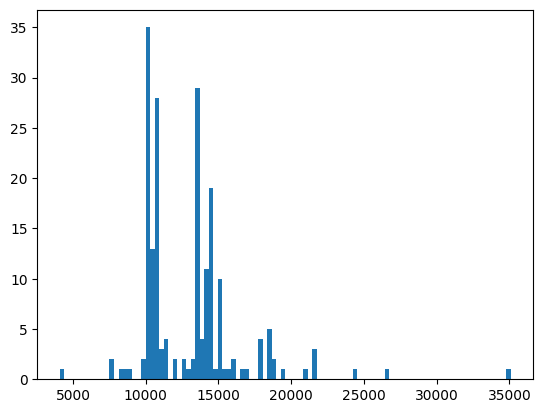

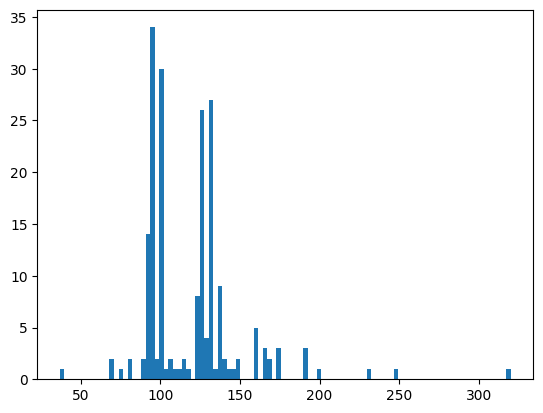

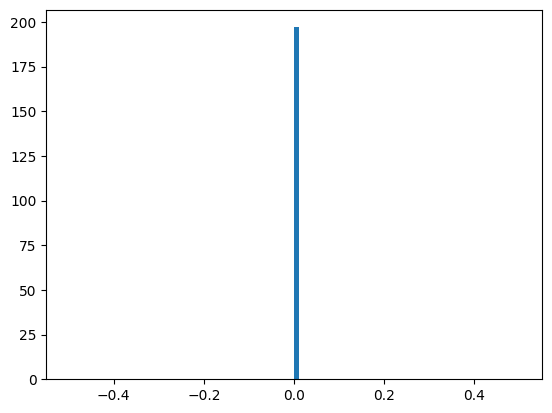

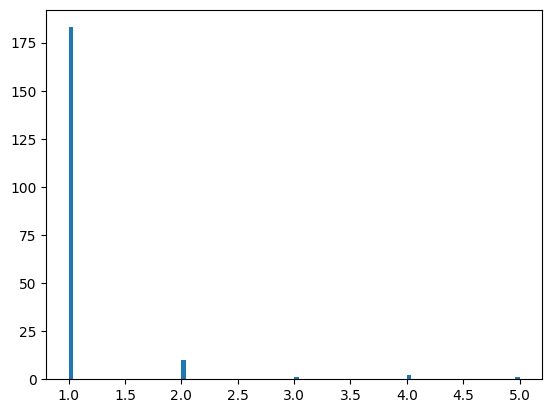

In [ ]:
import matplotlib.pyplot as plt

reviewed = ["grey" if "unreviewed" in entry["entryType"] else "gold" for entry in data["results"]]

mass = [entry["sequence"]["molWeight"] for entry in data["results"]]
plt.hist(mass, bins=100)
plt.show()

length = [entry["sequence"]["length"] for entry in data["results"]]
plt.hist(length, bins=100)
plt.show()

n_cat = [len(entry.get("comments", [])) for entry in data["results"]]
plt.hist(n_cat, bins=100)
plt.show()

score = [entry["annotationScore"] for entry in data["results"]]
plt.hist(score, bins=100)
plt.show()

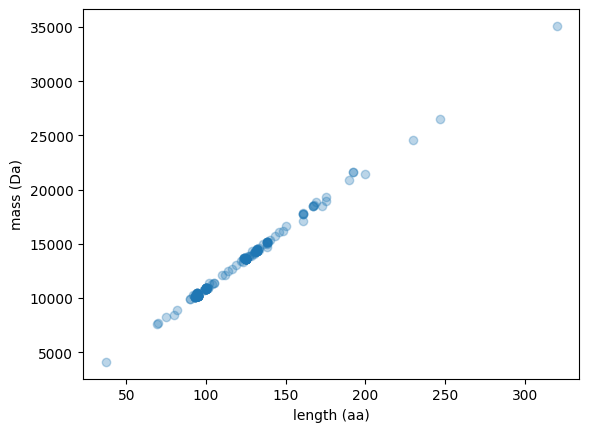

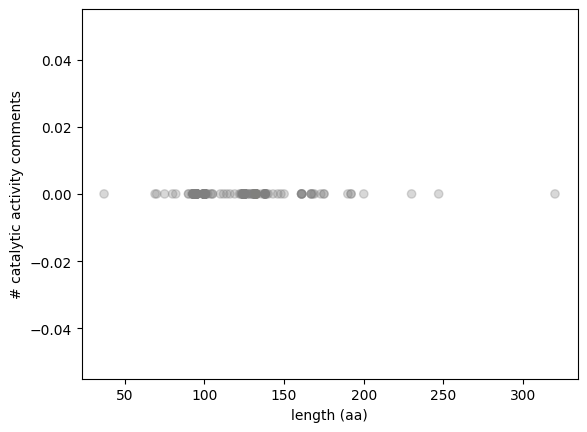

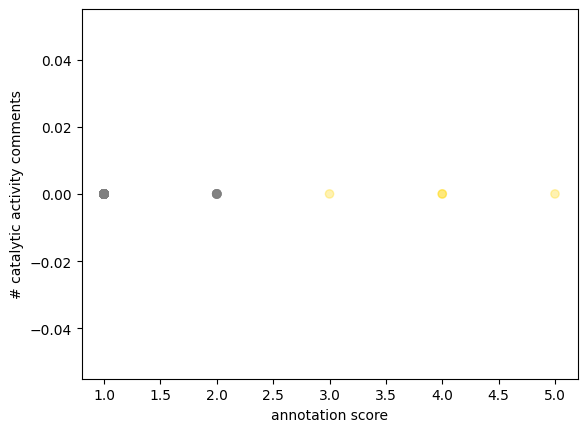

In [ ]:
import matplotlib.pyplot as plt
import requests

WEBSITE_API = "https://rest.uniprot.org/"

def get_url(url, **kwargs):
  response = requests.get(url, **kwargs);

  if not response.ok:
    print(response.text)
    response.raise_for_status()
    sys.exit()

  return response

r = get_url(f"{WEBSITE_API}/uniprotkb/stream?query=(gene:FAM19A5)&fields=mass,reviewed,length,cc_catalytic_activity,annotation_score")
data = r.json()

reviewed = ["grey" if "unreviewed" in entry["entryType"] else "gold" for entry in data["results"]]
mass = [entry["sequence"]["molWeight"] for entry in data["results"]]
length = [entry["sequence"]["length"] for entry in data["results"]]
n_cat = [len(entry.get("comments", [])) for entry in data["results"]]
score = [entry["annotationScore"] for entry in data["results"]]


plt.scatter(length, mass, alpha=0.3)
plt.xlabel("length (aa)")
plt.ylabel("mass (Da)")
plt.show()

plt.scatter(length, n_cat, c=reviewed, alpha=0.3)
plt.xlabel("length (aa)")
plt.ylabel("# catalytic activity comments")
plt.show()

plt.scatter(score, n_cat, c=reviewed, alpha=0.3)
plt.xlabel("annotation score")
plt.ylabel("# catalytic activity comments")
plt.show()